# KIPS Promiscuity Modeling

## Imports

In [1]:
import os
import io
import json
from pathlib import Path
from collections import defaultdict
from functools import partial
from itertools import product

import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.utils import resample
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, accuracy_score, precision_recall_curve,
    roc_curve, mean_squared_error, mean_absolute_error, r2_score,
)

import xgboost as xgb
import optuna
import shap
from kneed import KneeLocator
from tqdm.auto import tqdm
from IPython.display import display

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.text import Text
import seaborn as sns
from PIL import Image
from rdkit import Chem, RDLogger, rdBase
from rdkit.Chem import AllChem, Draw, DataStructs, BRICS
from rdkit.Chem.Draw import SimilarityMaps
from rdkit.Chem.MolStandardize import rdMolStandardize

RDLogger.DisableLog('rdApp.*')
optuna.logging.set_verbosity(optuna.logging.WARNING)

c:\Users\bstrickland\miniconda3\envs\KIPS\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Input path

In [2]:
PROJECT_DIR = Path.cwd() if (Path.cwd() / 'Data').is_dir() else Path.cwd().parent
DATA_DIR = str(PROJECT_DIR / 'Data')
KIPS_CURATED_CSV = str(PROJECT_DIR / 'Output' / 'Intermediate' / 'KIPS_Curated' / 'KIPS_Curated_SI65.csv')

SMILES_COL = 'SMILES_standardized'
TARGET_COL = 'is_promiscuous'

## Output paths

In [3]:
OUTPUT_DIR = PROJECT_DIR / 'Output'
SUPPORTING_DIR = OUTPUT_DIR / 'Supporting'
INTERMEDIATE_DIR = OUTPUT_DIR / 'Intermediate'
DIRS = {
    'regression': SUPPORTING_DIR / 'Regression_Model',
    'model': SUPPORTING_DIR / 'Final_Model',
    'eval': SUPPORTING_DIR / 'Final_Model_Performance',
    'shap': SUPPORTING_DIR / 'Final_Model_Analysis',
    'robustness': SUPPORTING_DIR / 'Robustness',
    'final_model': INTERMEDIATE_DIR / 'Final_Model',
    'tables_main': OUTPUT_DIR / 'Tables' / 'Main',
    'tables_information': OUTPUT_DIR / 'Tables' / 'Supplementary_Information',
    'tables_data': OUTPUT_DIR / 'Tables' / 'Supplementary_Data',
    'panels': INTERMEDIATE_DIR / 'Figure_Panels',
    'shap_heatmaps': INTERMEDIATE_DIR / 'Figure_Panels' / 'Heatmaps',
    'figures_main': OUTPUT_DIR / 'Figures' / 'Main',
    'figures_supplementary': OUTPUT_DIR / 'Figures' / 'Supplementary',
}

for folder in DIRS.values():
    folder.mkdir(parents=True, exist_ok=True)

## Parameters

In [4]:
RANDOM_SEED = 2026
N_FOLDS = 5
N_OPTUNA_TRIALS = 500
N_ROBUSTNESS_TRIALS = 500
N_REGRESSION_TRIALS = 500
N_BOOTSTRAP = 1000

FP_RADIUS = 2
FP_NBITS = 1024
FP_TYPES = ['ECFP', 'FCFP']
RADII = [2, 3, 4]
NBITS = [1024, 2048, 4096]
REGRESSION_FP_CONFIG = dict(FP_Type='ECFP', Radius=FP_RADIUS, nBits=FP_NBITS, useChirality=True)

SHAP_UNIT = 'log-odds'
SHAP_COLORMAP = 'bwr'
SHAP_CONTOUR_LINES = 10
MIN_COMPOUNDS_PER_BRICS_FRAGMENT = 10
FIGURE8_N_FRAGMENTS = 9
WATERFALL_MAX_FEATURES = 15
KNEEDLE_SENSITIVITY = 5.0

## Figure style

In [5]:
MAIN_COLORS = {
    'black': '#000000',
    'orange': '#E69F00',
    'skyblue': '#56B4E9',
    'bluishgreen': '#009E73',
    'yellow': '#F0E442',
    'blue': '#0072B2', 
    'vermillion': '#D55E00', 
    'reddishpurple': '#CC79A7'
}

plt.style.use('default')
plt.rcParams.update({
    'font.size': 7,
    'font.family': 'Arial',
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'axes.titlesize': 7,
    'figure.dpi': 450,
    'savefig.dpi': 450,
    'savefig.bbox': 'tight',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

def save_figure(fig, folder, stem):
    for extension in ('pdf', 'png'):
        fig.savefig(Path(folder) / f'{stem}.{extension}', bbox_inches='tight')

def style_axis(ax, letter=None):
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(length=3, width=.6)
    if letter:
        ax.text(-.10, 1.04, letter, transform=ax.transAxes,
                fontsize=9, fontweight='bold', va='bottom')

## Fingerprints and cross-validation

In [6]:
def make_fp(mol, config, bit_info=None):
    return AllChem.GetMorganFingerprintAsBitVect(
        mol, config['Radius'], nBits=config['nBits'],
        useChirality=config['useChirality'], useFeatures=config['FP_Type'] == 'FCFP',
        bitInfo=bit_info if bit_info is not None else {})

def fp_to_arr(fp):
    row = np.zeros(fp.GetNumBits(), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, row)
    return row

def fingerprint_matrix(molecules, config):
    return np.array([fp_to_arr(make_fp(mol, config)) for mol in molecules])

def make_classifier(name, labels, params):
    if name == 'XGBoost':
        return xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss',
            random_state=RANDOM_SEED, n_jobs=-1,
            scale_pos_weight=np.sum(labels == 0) / np.sum(labels == 1), **params)
    return RandomForestClassifier(class_weight='balanced', random_state=RANDOM_SEED,
                                  n_jobs=-1, **params)

def classifier_trial_params(trial):
    return dict(
        n_estimators=1000,
        max_depth=trial.suggest_int('max_depth', 5, 10),
        learning_rate=trial.suggest_float('learning_rate', .01, .3, log=True),
        min_child_weight=trial.suggest_float('min_child_weight', 0.5, 10, log=True),
        subsample=trial.suggest_float('subsample', .5, 1.),
        colsample_bynode=trial.suggest_float('colsample_bynode', .1, 1.),
        gamma=trial.suggest_float('gamma', 1e-3, 10., log=True),
        reg_alpha=trial.suggest_float('reg_alpha', 1e-3, 10., log=True),
        reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 10., log=True))

def oof_predictions(matrix, labels, params, folds, model_name='XGBoost'):
    probabilities = np.empty(len(labels))
    for train_idx, val_idx in folds:
        model = make_classifier(model_name, labels[train_idx], params)
        model.fit(matrix[train_idx], labels[train_idx])
        probabilities[val_idx] = model.predict_proba(matrix[val_idx])[:, 1]
    return probabilities

def classifier_objective(trial, matrix, labels, folds):
    probabilities = oof_predictions(matrix, labels, classifier_trial_params(trial), folds)
    return float(np.mean([average_precision_score(labels[val], probabilities[val])
                          for _, val in folds]))

def select_decision_threshold(labels, probabilities):
    thresholds = np.linspace(0.05, 0.95, 181)
    scores = np.array([matthews_corrcoef(labels, probabilities >= t) for t in thresholds])
    return float(thresholds[np.argmax(scores)]), scores, thresholds

def calc_metrics(labels, probabilities, threshold):
    predictions = probabilities >= threshold
    return {
        'ROC_AUC': roc_auc_score(labels, probabilities),
        'PR_AUC': average_precision_score(labels, probabilities),
        'Accuracy': accuracy_score(labels, predictions),
        'Precision': precision_score(labels, predictions, zero_division=0),
        'Recall': recall_score(labels, predictions, zero_division=0),
        'F1': f1_score(labels, predictions, zero_division=0),
        'MCC': matthews_corrcoef(labels, predictions),
    }

## Stratified split
Stratified 80/20 split, w/ 5-fold CV

In [7]:
kips_df = pd.read_csv(KIPS_CURATED_CSV)
kips_df['mol'] = kips_df[SMILES_COL].apply(Chem.MolFromSmiles)
kips_df = kips_df.dropna(subset=['mol']).reset_index(drop=True)
kips_df[TARGET_COL] = kips_df[TARGET_COL].astype(int)
assert kips_df['InChI_Key'].is_unique
df_train, df_test = train_test_split(kips_df, test_size=.2, stratify=kips_df[TARGET_COL], random_state=RANDOM_SEED)
df_train, df_test = df_train.reset_index(drop=True), df_test.reset_index(drop=True)
y_train, y_test = df_train[TARGET_COL].to_numpy(), df_test[TARGET_COL].to_numpy()
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
cv_folds = list(skf.split(df_train, y_train))
cv_fold_col = np.empty(len(y_train), dtype=int)
for fold, (_, val_idx) in enumerate(cv_folds):
    cv_fold_col[val_idx] = fold
split_export = pd.concat([df_train[['Compound ID', 'InChI_Key', TARGET_COL]].assign(Split='Train', CV_fold=cv_fold_col), df_test[['Compound ID', 'InChI_Key', TARGET_COL]].assign(Split='Test', CV_fold=-1),], ignore_index=True)
split_export.to_csv(DIRS['final_model'] / 'Split_Assignments.csv', index=False)
print(f'Train: {len(y_train):,} ({y_train.mean():.1%} promiscuous) | '
      f'Test: {len(y_test):,} ({y_test.mean():.1%} promiscuous)')

Train: 1,230 (11.5% promiscuous) | Test: 308 (11.4% promiscuous)


## SI65 Regression

c:\Users\bstrickland\miniconda3\envs\KIPS\lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  optuna_warn(
Best trial: 446. Best value: 0.0647358: 100%|██████████| 500/500 [1:40:17<00:00, 12.03s/it]


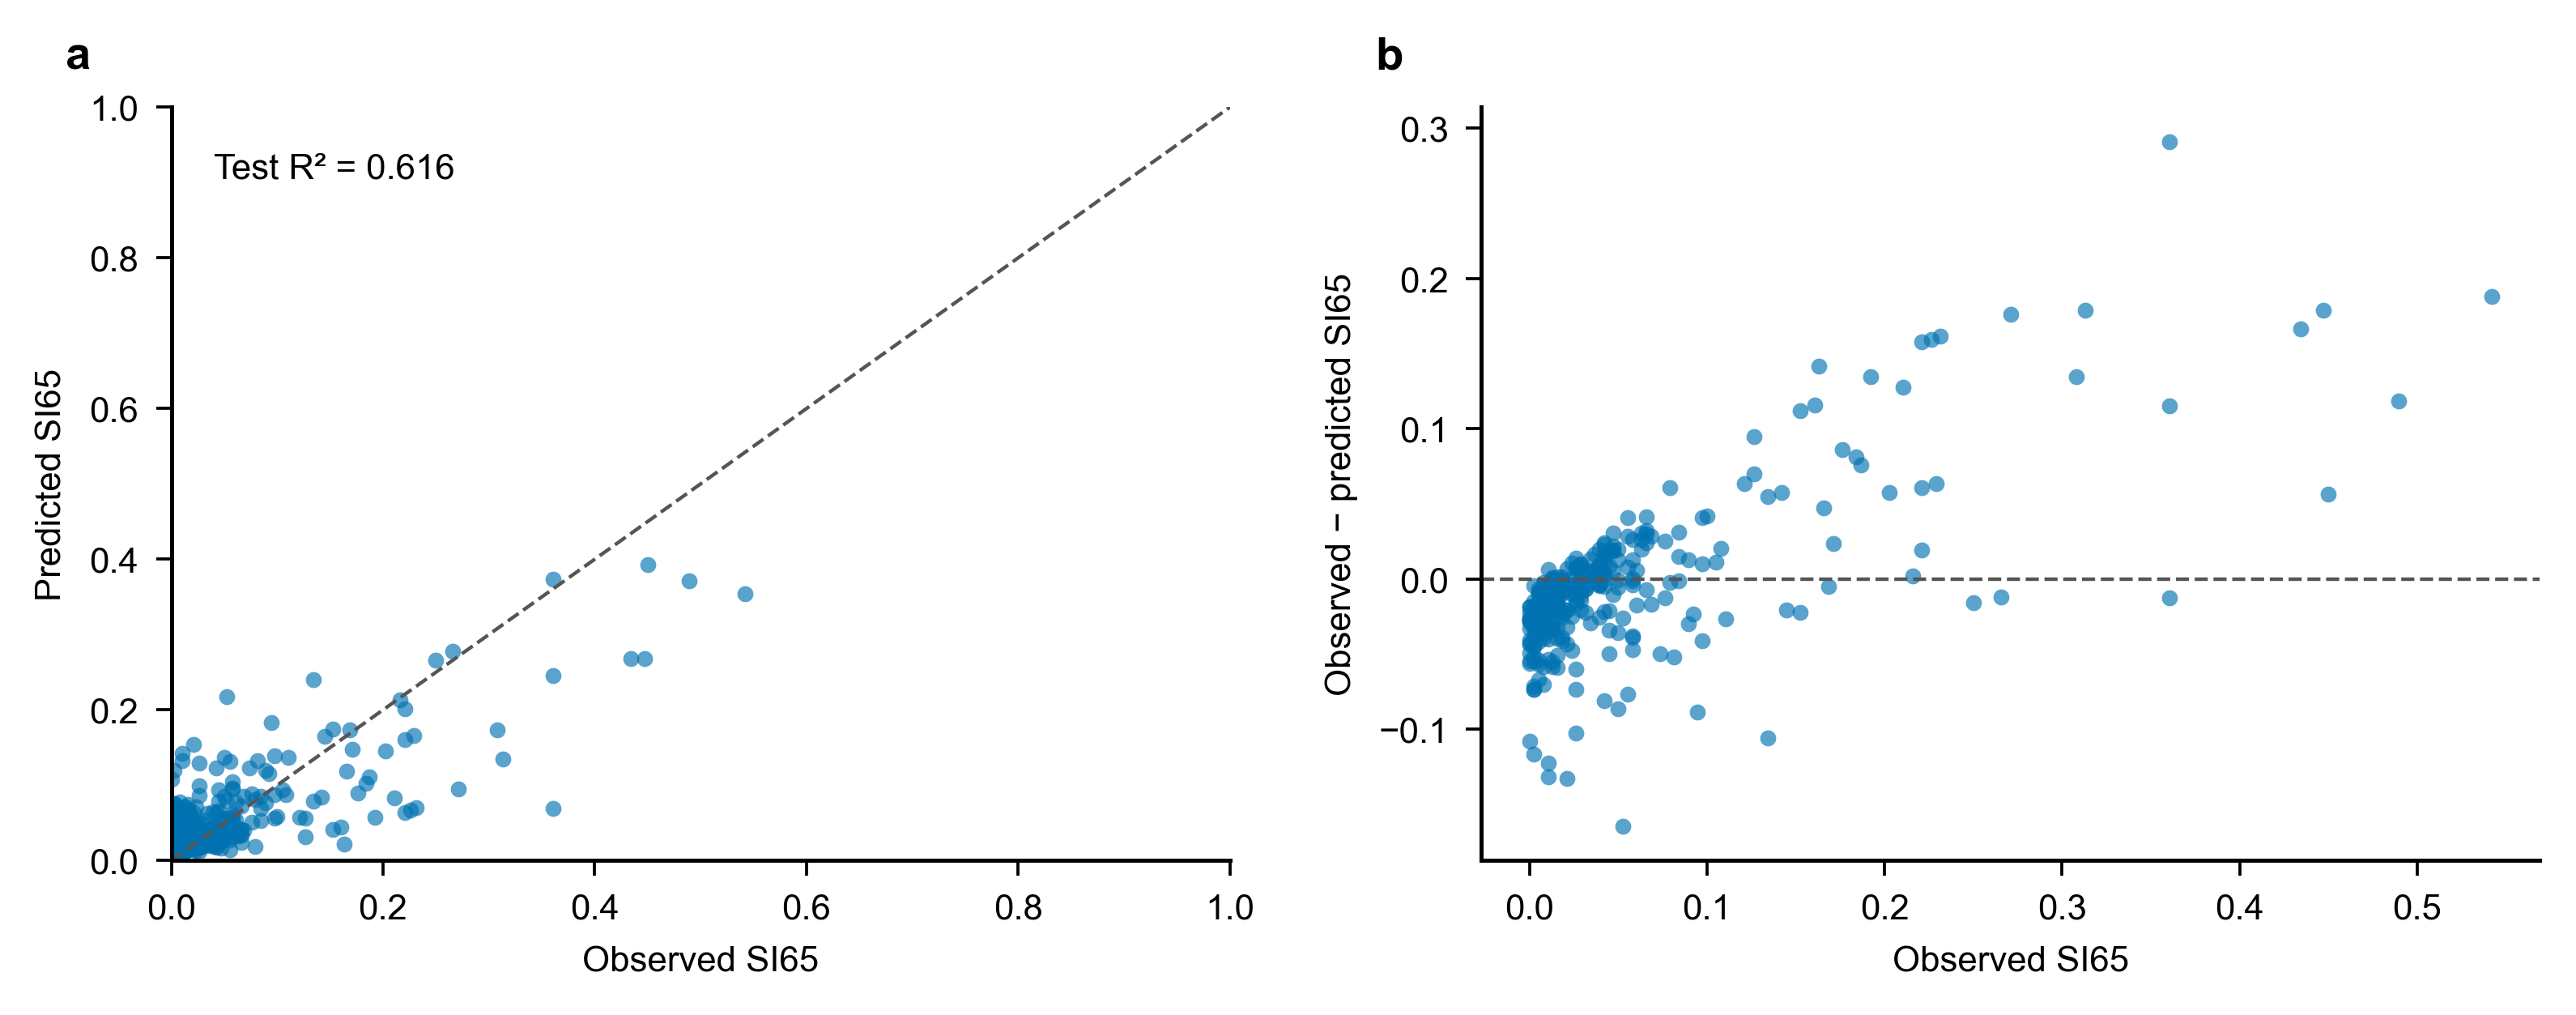

,MAE,RMSE,R2
Model,,,
XGBoost,0.034347,0.052680,0.615824
Training mean,0.056312,0.085187,-0.004583


In [8]:
X_reg_train = fingerprint_matrix(df_train['mol'], REGRESSION_FP_CONFIG)
X_reg_test = fingerprint_matrix(df_test['mol'], REGRESSION_FP_CONFIG)
y_train_si65 = df_train['SI65'].to_numpy()
y_test_si65 = df_test['SI65'].to_numpy()

def regression_objective(trial):
    model = xgb.XGBRegressor(objective='reg:squarederror', random_state=RANDOM_SEED, n_jobs=-1, **classifier_trial_params(trial))
    return -cross_val_score(model, X_reg_train, y_train_si65, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()

regression_study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED, multivariate=True))
regression_study.optimize(regression_objective, n_trials=N_REGRESSION_TRIALS, show_progress_bar=True)
regression_params = classifier_trial_params(optuna.trial.FixedTrial(regression_study.best_params))
regression_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=RANDOM_SEED, n_jobs=-1, **regression_params).fit(X_reg_train, y_train_si65)
regression_baseline = DummyRegressor(strategy='mean').fit(X_reg_train, y_train_si65)
regression_predictions = {'XGBoost': regression_model.predict(X_reg_test), 'Training mean': regression_baseline.predict(X_reg_test)}
regression_metrics = pd.DataFrame([dict(Model=name, MAE=mean_absolute_error(y_test_si65, prediction),RMSE=np.sqrt(mean_squared_error(y_test_si65, prediction)), R2=r2_score(y_test_si65, prediction))
    for name, prediction in regression_predictions.items()]).set_index('Model')
regression_metrics.to_csv(DIRS['regression'] / 'Test_Metrics.csv')
regression_study.trials_dataframe().to_csv(DIRS['regression'] / 'Optuna_Trials.csv', index=False)
pd.DataFrame({'Compound ID': df_test['Compound ID'], 'SI65': y_test_si65, **regression_predictions}).to_csv(DIRS['regression'] / 'Test_Predictions.csv', index=False)
(DIRS['regression'] / 'Configuration.json').write_text(json.dumps({'fingerprint': REGRESSION_FP_CONFIG, 'params': regression_params,'CV_RMSE': regression_study.best_value, 'seed': RANDOM_SEED}, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(7.08, 2.8))
pred = regression_predictions['XGBoost']
low, high = min(0., float(pred.min())), max(1., float(pred.max()))
axes[0].scatter(y_test_si65, pred, s=10, alpha=.65, color=MAIN_COLORS['blue'], linewidths=0)
axes[0].plot([low, high], [low, high], '--', color='#555555', lw=.7)
axes[0].set(xlim=(low, high), ylim=(low, high), xlabel='Observed SI65', ylabel='Predicted SI65')
axes[0].text(.04, .94, f'Test R² = {regression_metrics.loc["XGBoost", "R2"]:.3f}', transform=axes[0].transAxes, va='top')
axes[1].scatter(y_test_si65, y_test_si65 - pred, s=10, alpha=.65, color=MAIN_COLORS['blue'], linewidths=0)
axes[1].axhline(0, color='#555555', lw=.7, ls='--')
axes[1].set(xlabel='Observed SI65', ylabel='Observed − predicted SI65')
for ax, letter in zip(axes, 'ab'):
    style_axis(ax, letter)
fig.tight_layout(w_pad=2.)
save_figure(fig, DIRS['figures_supplementary'], 'Supplementary_Figure_13_Regression_Model')
plt.show()

display(regression_metrics)

## Fingerprint & model grid search

In [9]:
all_results = []
with tqdm(total=len(FP_TYPES) * len(RADII) * len(NBITS) * 2, desc='Grid search') as progress:
    for family, radius, nbits in product(FP_TYPES, RADII, NBITS):
        config = dict(FP_Type=family, Radius=radius, nBits=nbits, useChirality=True)
        matrix = fingerprint_matrix(df_train['mol'], config)
        for model_name in ('XGBoost', 'RandomForest'):
            probability = oof_predictions(matrix, y_train, dict(n_estimators=100, max_depth=6), cv_folds, model_name)
            fold_ap = [average_precision_score(y_train[val], probability[val]) for _, val in cv_folds]
            fold_roc = [roc_auc_score(y_train[val], probability[val]) for _, val in cv_folds]
            all_results.append(dict(Model=model_name, **config, Mean_PR_AUC=np.mean(fold_ap),
                Std_PR_AUC=np.std(fold_ap), Mean_ROC_AUC=np.mean(fold_roc),
                Std_ROC_AUC=np.std(fold_roc), PR_AUC_folds=fold_ap))
            progress.update(1)
df_results = pd.DataFrame(all_results).sort_values('Mean_PR_AUC', ascending=False).reset_index(drop=True)
configuration_columns = ['Model', 'FP_Type', 'Radius', 'nBits', 'Mean_PR_AUC', 'Std_PR_AUC', 'Mean_ROC_AUC', 'Std_ROC_AUC']
df_results[configuration_columns].head(5).set_axis(
    ['Model', 'Fingerprint', 'Radius', '# of Bits', 'PR-AUC (Mean)', 'PR-AUC (SD)', 'ROC-AUC (Mean)', 'ROC-AUC (SD)'], axis=1
).to_csv(DIRS['tables_main'] / 'Table_1_Top_Model_Configurations.csv', index=False, float_format='%.3f')
df_results[configuration_columns].set_axis(
    ['Model', 'FP Type', 'FP Radius', 'FP nBits', 'PR AUC (Mean)', 'PR-AUC (SD)', 'ROC-AUC (Mean)', 'ROC-AUC (SD)'], axis=1
).to_csv(DIRS['tables_data'] / 'Supplementary_Data_Table_10_Model_Configurations.csv', index=False, float_format='%.3f')
display(df_results.drop(columns=['PR_AUC_folds', 'useChirality']).head(20))

Grid search: 100%|██████████| 36/36 [01:13<00:00,  2.03s/it]


,Model,FP_Type,Radius,nBits,Mean_PR_AUC,Std_PR_AUC,Mean_ROC_AUC,Std_ROC_AUC
0,XGBoost,ECFP,2,1024,0.599800,0.082747,0.853950,0.063119
1,XGBoost,FCFP,2,1024,0.596521,0.052849,0.847191,0.045887
2,XGBoost,FCFP,2,2048,0.595710,0.079646,0.854249,0.037335
3,XGBoost,ECFP,2,4096,0.593731,0.067270,0.847649,0.051397
4,XGBoost,FCFP,3,1024,0.587695,0.076474,0.859838,0.055318
5,XGBoost,ECFP,3,1024,0.586706,0.064763,0.845171,0.053241
6,XGBoost,FCFP,3,4096,0.586331,0.061083,0.840481,0.049637
7,XGBoost,ECFP,3,2048,0.584376,0.082363,0.850901,0.062300
8,XGBoost,ECFP,4,1024,0.582543,0.057501,0.838002,0.046555
9,XGBoost,FCFP,2,4096,0.581531,0.058592,0.849921,0.043595


## Manual FP Selection
Adjust `SELECTED_FP_TYPE`, `SELECTED_RADIUS`, `SELECTED_NBITS` as required

In [10]:
SELECTED_FP_TYPE = 'ECFP'
SELECTED_RADIUS = 2
SELECTED_NBITS = 1024
SELECTED_FP_CONFIG = dict(FP_Type=SELECTED_FP_TYPE, Radius=SELECTED_RADIUS,
                          nBits=SELECTED_NBITS, useChirality=True)
assert SELECTED_FP_TYPE in FP_TYPES
print(SELECTED_FP_CONFIG)

X_train = fingerprint_matrix(df_train['mol'], SELECTED_FP_CONFIG)
test_bit_info, test_rows = [], []
for mol in df_test['mol']:
    info = {}
    test_rows.append(fp_to_arr(make_fp(mol, SELECTED_FP_CONFIG, info)))
    test_bit_info.append(info)
X_test = np.array(test_rows)
feature_names = [f'Bit {i}' for i in range(SELECTED_NBITS)]

{'FP_Type': 'ECFP', 'Radius': 2, 'nBits': 1024, 'useChirality': True}


## Optuna hyperparameter optimization

In [11]:
study = optuna.create_study(direction='maximize', study_name='XGBoost_SI65_main', sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED, multivariate=True))
study.optimize(partial(classifier_objective, matrix=X_train, labels=y_train, folds=cv_folds), n_trials=N_OPTUNA_TRIALS, show_progress_bar=True)
best_params = classifier_trial_params(optuna.trial.FixedTrial(study.best_params))
(DIRS['model'] / 'Best_Params.json').write_text(json.dumps(best_params, indent=2))
study.trials_dataframe().to_csv(DIRS['model'] / 'Optuna_Trials.csv', index=False)
print(f'Best trial: {study.best_trial.number}; mean 5-fold CV PR-AUC = {study.best_value:.4f}')

c:\Users\bstrickland\miniconda3\envs\KIPS\lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  optuna_warn(
Best trial: 130. Best value: 0.632129: 100%|██████████| 500/500 [3:03:03<00:00, 21.97s/it]  

Best trial: 130; mean 5-fold CV PR-AUC = 0.6321


## Out-of-fold threshold selection
Maximizing MCC

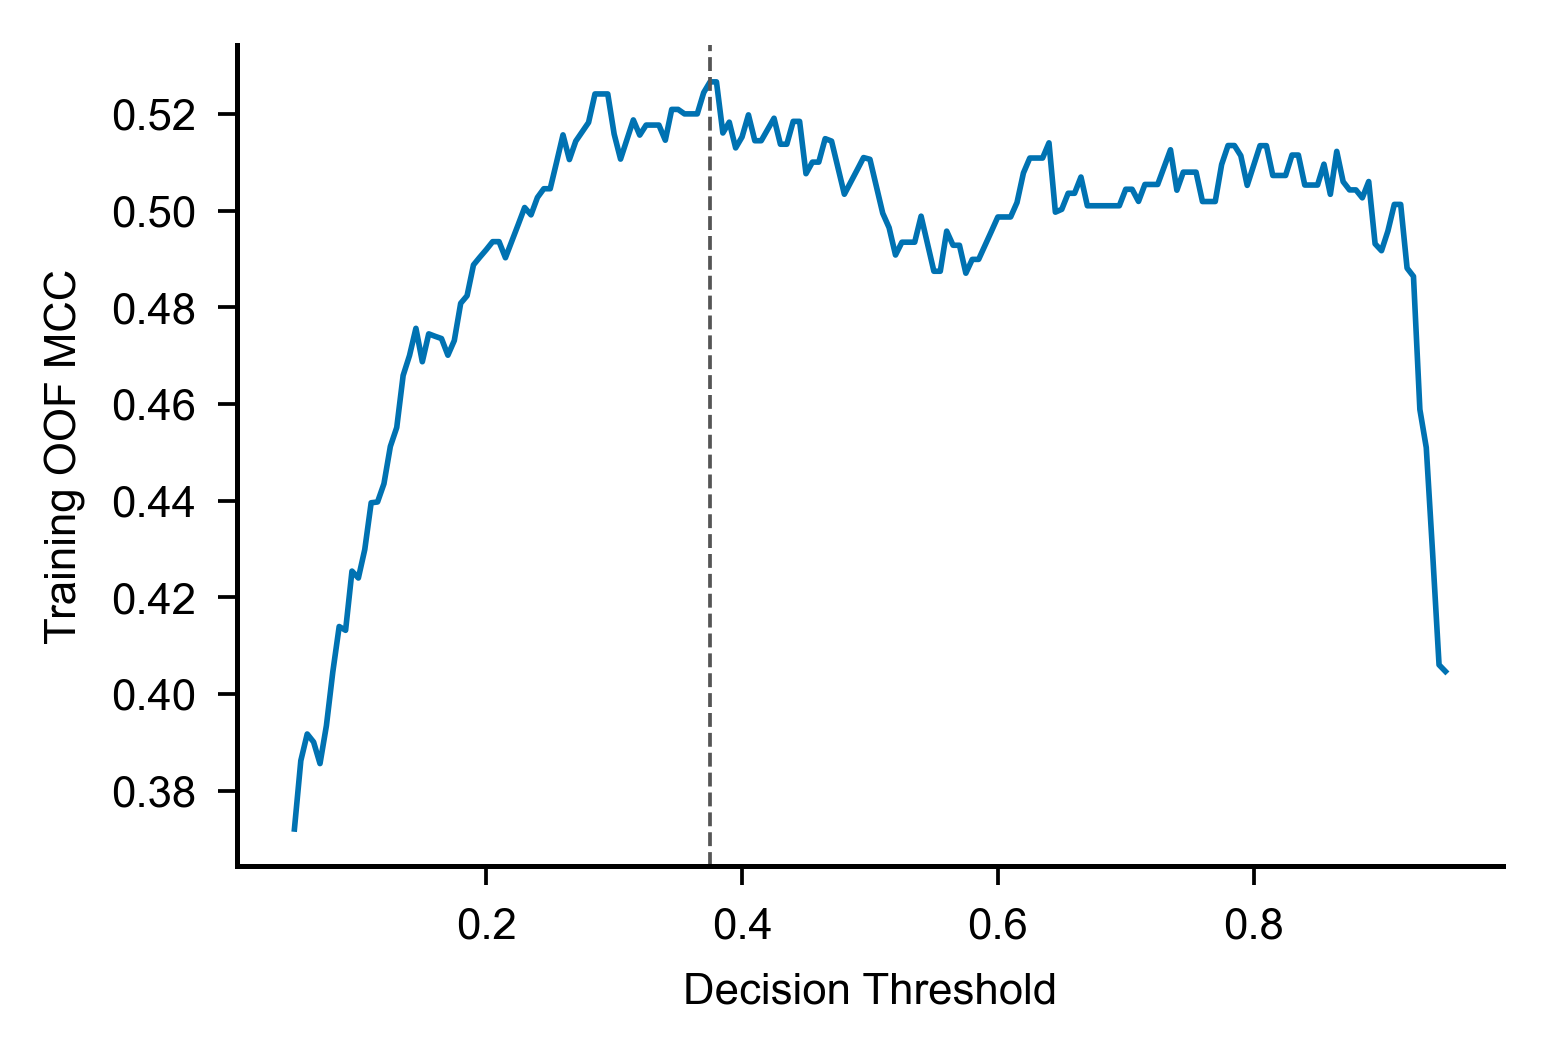

Locked prediction threshold: 0.375


In [12]:
oof_proba = oof_predictions(X_train, y_train, best_params, cv_folds)
DECISION_THRESHOLD, mcc_scores, thresholds = select_decision_threshold(y_train, oof_proba)
fig, ax = plt.subplots(figsize=(3.45, 2.36))
ax.plot(thresholds, mcc_scores, color=MAIN_COLORS['blue'], lw=.9)
ax.axvline(DECISION_THRESHOLD, color='#555555', ls='--', lw=.6)
ax.set(xlabel='Decision Threshold', ylabel='Training OOF MCC')
style_axis(ax)
fig.tight_layout()
save_figure(fig, DIRS['figures_supplementary'], 'Supplementary_Figure_12_Threshold_Selection')
plt.show()
print(f'Locked prediction threshold: {DECISION_THRESHOLD:.3f}')

pd.DataFrame({'Compound ID': df_train['Compound ID'], 'Label': y_train, 'CV_fold': cv_fold_col, 'OOF_probability': oof_proba}).to_csv(DIRS['eval'] / 'OOF_Predictions.csv', index=False)

## Test set evaluation and model export

In [13]:
final_model = make_classifier('XGBoost', y_train, best_params)
final_model.fit(X_train, y_train)
y_pred_proba = final_model.predict_proba(X_test)[:, 1]
y_pred_class = (y_pred_proba >= DECISION_THRESHOLD).astype(int)
df_test['pred_proba'], df_test['pred_class'] = y_pred_proba, y_pred_class
metrics = calc_metrics(y_test, y_pred_proba, DECISION_THRESHOLD)
test_results = pd.Series(metrics, name='Value').rename({'ROC_AUC': 'ROC-AUC', 'PR_AUC': 'PR-AUC'})
df_test[['Compound ID', 'InChI_Key', SMILES_COL, TARGET_COL, 'pred_proba', 'pred_class']].to_csv(
    DIRS['eval'] / 'Test_Predictions.csv', index=False)

final_model.save_model(DIRS['final_model'] / 'Model.json')
(DIRS['final_model'] / 'Configuration.json').write_text(json.dumps({
    'model': 'XGBoost', 'fingerprint': SELECTED_FP_CONFIG, 'params': best_params,
    'prediction_threshold': DECISION_THRESHOLD, 'seed': RANDOM_SEED,
    'optuna_trials': N_OPTUNA_TRIALS, 'CV_folds': N_FOLDS, 'test_size': .2,
    'standardization': ['ChargeParent', 'Uncharger', 'canonical isomeric SMILES'],
    'input': str(Path(KIPS_CURATED_CSV).relative_to(PROJECT_DIR).as_posix()), 'train_n': len(df_train), 'test_n': len(df_test),
    'rdkit_version': rdBase.rdkitVersion, 'xgboost_version': xgb.__version__,
}, indent=2))

display(test_results.to_frame())

,Value
ROC-AUC,0.856410
PR-AUC,0.630990
Accuracy,0.892857
Precision,0.527778
Recall,0.542857
F1,0.535211
MCC,0.474735


## Bootsrap test set

In [14]:
boot_results = []
boot_tprs, boot_precs = [], []
base_fpr    = np.linspace(0, 1, 101)
base_recall = np.linspace(0, 1, 101)

for i in tqdm(range(N_BOOTSTRAP), desc="Bootstrap"):
    idx = resample(np.arange(len(y_test)), replace=True, random_state=RANDOM_SEED + i)
    if len(np.unique(y_test[idx])) < 2:
        continue
    boot_results.append(calc_metrics(y_test[idx], y_pred_proba[idx], DECISION_THRESHOLD))

    fpr, tpr, _ = roc_curve(y_test[idx], y_pred_proba[idx])
    boot_tprs.append(np.interp(base_fpr, fpr, tpr))

    prec, rec, _ = precision_recall_curve(y_test[idx], y_pred_proba[idx])
    boot_precs.append(np.interp(base_recall, rec[::-1], prec[::-1]))

boot_tprs  = np.array(boot_tprs)
boot_precs = np.array(boot_precs)
df_boot    = pd.DataFrame(boot_results)

summary = pd.DataFrame({
    'Median':   df_boot.median(),
    'CI_lower': df_boot.quantile(0.025),
    'CI_upper': df_boot.quantile(0.975),
})
bootstrap = summary.rename(index={'ROC_AUC': 'ROC-AUC', 'PR_AUC': 'PR-AUC'})

table_2_metrics = ['ROC-AUC', 'PR-AUC', 'Precision', 'Recall', 'F1', 'MCC']
pd.DataFrame({
    'Metric': table_2_metrics,
    'Test': [f'{test_results[metric]:.3f}' for metric in table_2_metrics],
    'Bootstrap median': [f"{bootstrap.loc[metric, 'Median']:.3f}" for metric in table_2_metrics],
    'Bootstrap 95% CI': [f"({bootstrap.loc[metric, 'CI_lower']:.3f}-{bootstrap.loc[metric, 'CI_upper']:.3f})" for metric in table_2_metrics],
}).to_csv(DIRS['tables_main'] / 'Table_2_Test_Set_Performance.csv', index=False)

Bootstrap: 100%|██████████| 1000/1000 [00:10<00:00, 99.01it/s]


## Boostrap PR-AUC / ROC-AUC Curves

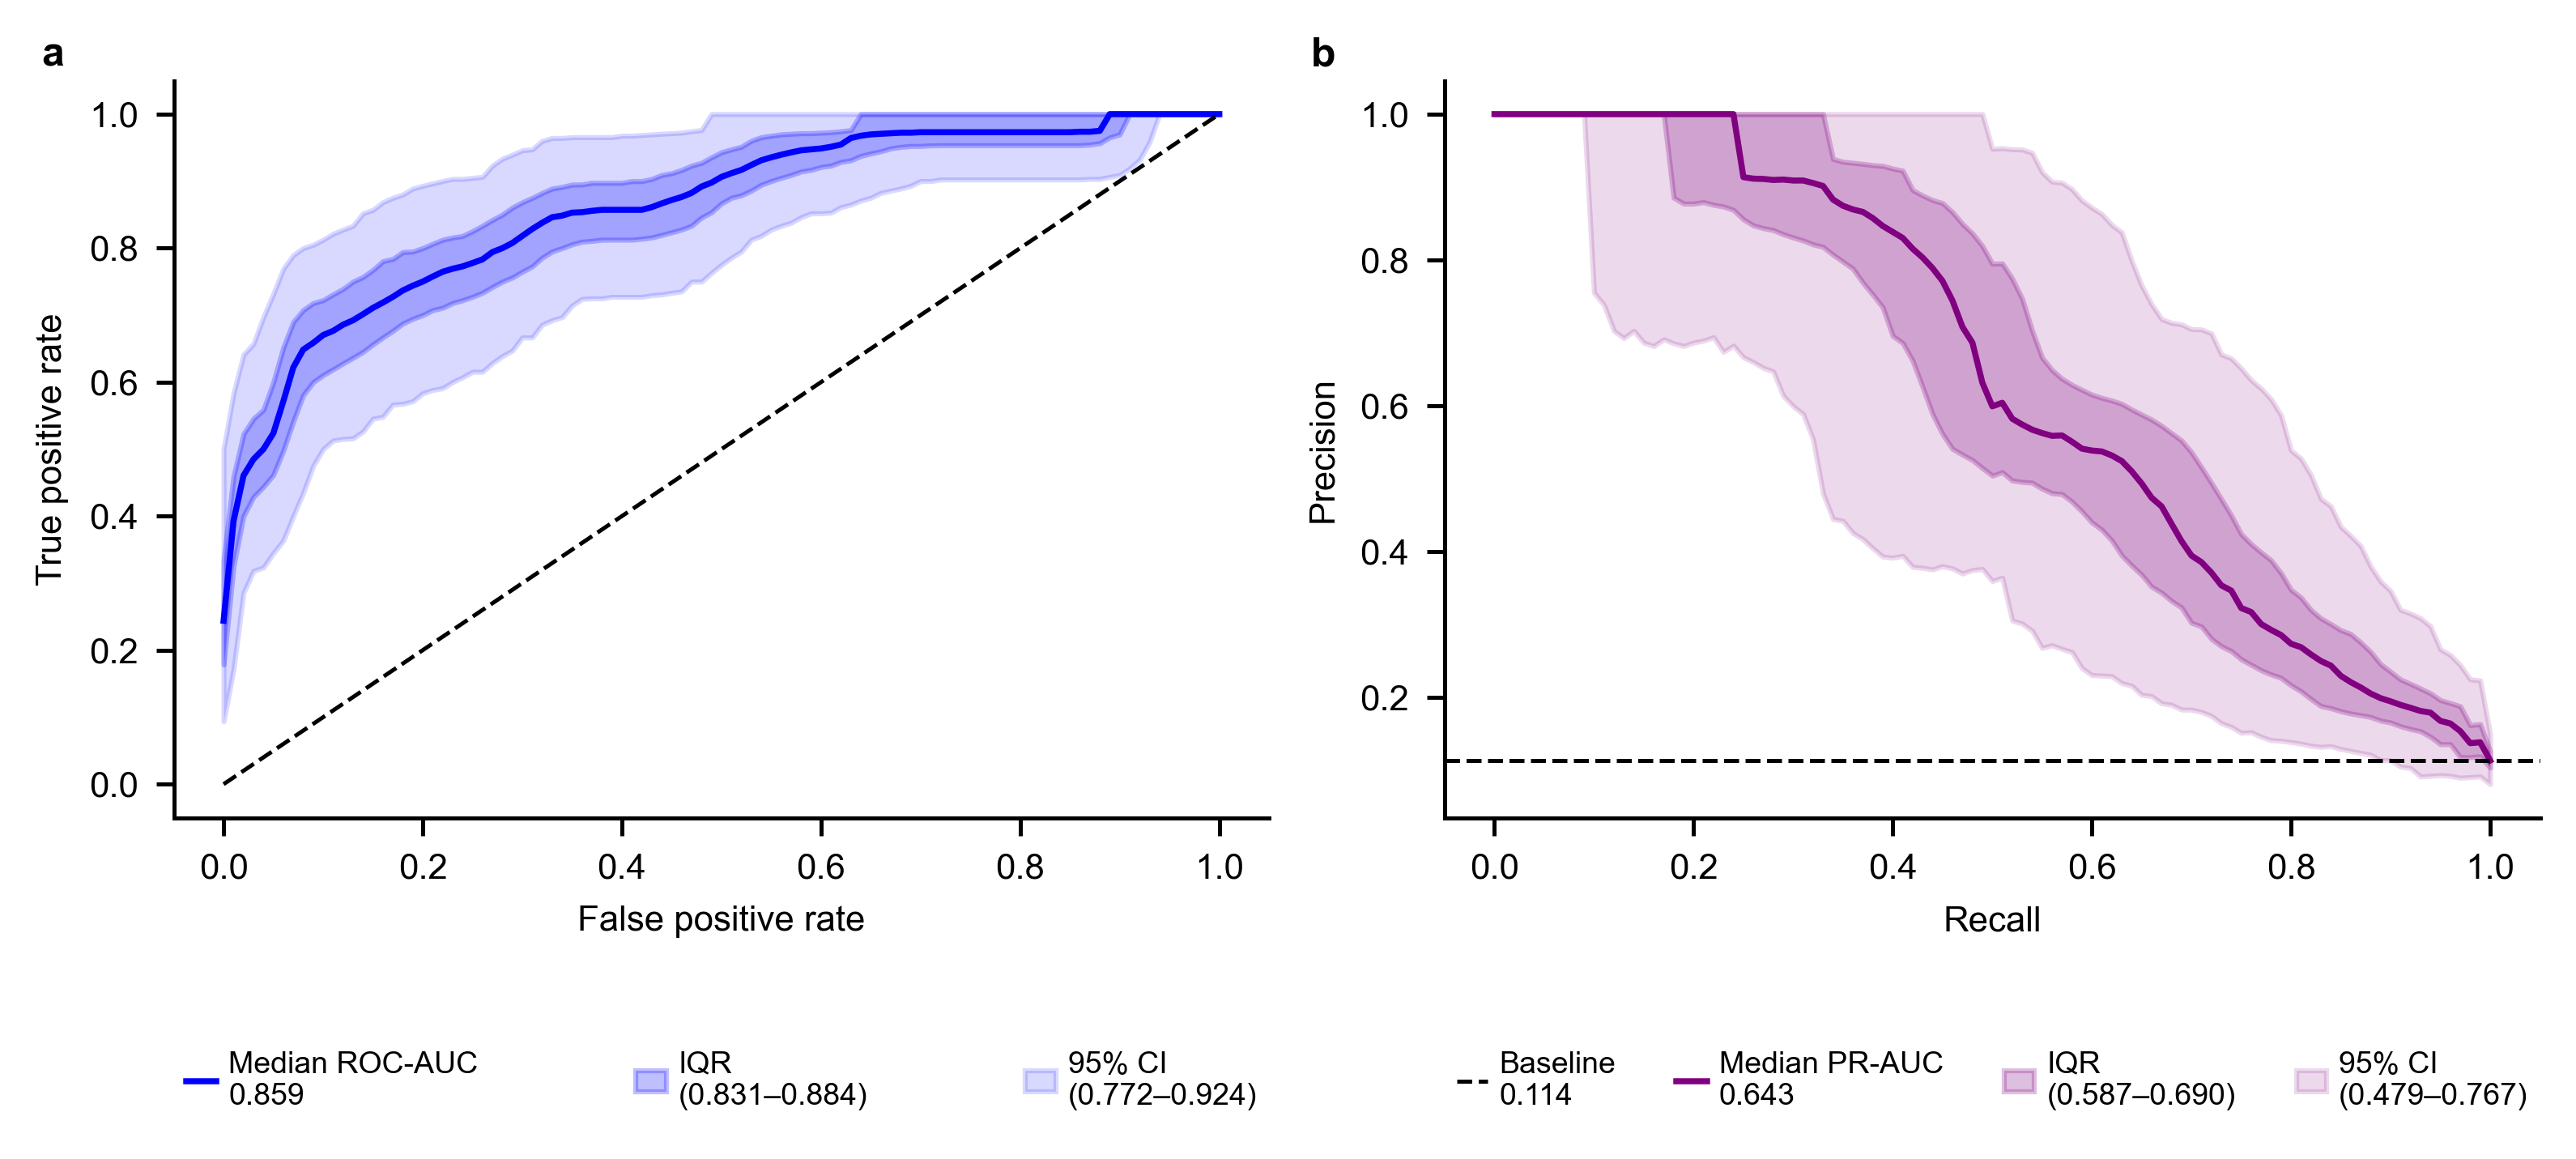

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.08, 3.4))

median_tpr = np.median(boot_tprs, axis=0)
roc_med    = df_boot['ROC_AUC'].median()
roc_ci     = df_boot['ROC_AUC'].quantile([0.025, 0.975]).values
roc_iqr    = df_boot['ROC_AUC'].quantile([0.25,  0.75]).values

ax1.plot(base_fpr, median_tpr, color='blue', linewidth=1.2,
         label=f'Median ROC-AUC = {roc_med:.3f}')
ax1.fill_between(base_fpr,
                 np.percentile(boot_tprs, 2.5,  axis=0),
                 np.percentile(boot_tprs, 97.5, axis=0),
                 color='blue', alpha=0.15,
                 label=f'95% CI ({roc_ci[0]:.3f}–{roc_ci[1]:.3f})')
ax1.fill_between(base_fpr,
                 np.percentile(boot_tprs, 25, axis=0),
                 np.percentile(boot_tprs, 75, axis=0),
                 color='blue', alpha=0.25,
                 label=f'IQR ({roc_iqr[0]:.3f}–{roc_iqr[1]:.3f})')
ax1.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax1.set_xlabel('False positive rate')
ax1.set_ylabel('True positive rate')

ax1.spines[['top', 'right']].set_visible(False)

median_prec = np.median(boot_precs, axis=0)
pr_med      = df_boot['PR_AUC'].median()
pr_ci       = df_boot['PR_AUC'].quantile([0.025, 0.975]).values
pr_iqr      = df_boot['PR_AUC'].quantile([0.25,  0.75]).values
baseline    = y_test.mean()

ax2.plot(base_recall, median_prec, color='purple', linewidth=1.2,
         label=f'Median PR-AUC = {pr_med:.3f}')
ax2.fill_between(base_recall,
                 np.percentile(boot_precs, 2.5,  axis=0),
                 np.percentile(boot_precs, 97.5, axis=0),
                 color='purple', alpha=0.15,
                 label=f'95% CI ({pr_ci[0]:.3f}–{pr_ci[1]:.3f})')
ax2.fill_between(base_recall,
                 np.percentile(boot_precs, 25, axis=0),
                 np.percentile(boot_precs, 75, axis=0),
                 color='purple', alpha=0.25,
                 label=f'IQR ({pr_iqr[0]:.3f}–{pr_iqr[1]:.3f})')
ax2.axhline(baseline, ls='--', color='k', lw=0.8, label=f'Baseline = {baseline:.3f}')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.spines[['top', 'right']].set_visible(False)

for i, ax in enumerate((ax1, ax2)):
    ax.text(-0.1, 1.06, 'ab'[i], transform=ax.transAxes,
            fontsize=8, fontweight='bold', va='top', ha='right')

plt.tight_layout(rect=(0, .20, 1, 1))
for ax, order in ((ax1, [0, 2, 1]), (ax2, [3, 0, 2, 1])):
    handles, labels = ax.get_legend_handles_labels()
    labels = [labels[j].replace(' = ', '\n').replace(' (', '\n(') for j in order]
    ax.legend([handles[j] for j in order], labels, ncol=len(order), mode='expand',
              loc='upper left', bbox_to_anchor=(0, -.30, 1, 0), borderaxespad=0,
              frameon=False, fontsize=6, handlelength=1., handletextpad=.4, columnspacing=.8)
plt.savefig(os.path.join(DIRS['figures_main'], 'Figure_7_Bootstrap_Curves.pdf'))
plt.savefig(os.path.join(DIRS['figures_main'], 'Figure_7_Bootstrap_Curves.png'))
plt.show()

## TreeSHAP

In [16]:
def explain_classifier(model, matrix, training_matrix):
    explainer = shap.TreeExplainer(model, training_matrix)
    return explainer(matrix)

explanation = explain_classifier(final_model, X_test, X_train)
explanation.feature_names = feature_names
shap_values_test = explanation.values
feature_summary = pd.DataFrame({'MeanAbsSHAP': np.abs(shap_values_test).mean(axis=0)},
                                index=pd.Index(range(SELECTED_NBITS), name='Bit'))
feature_summary.to_csv(DIRS['shap'] / 'Feature_Importance.csv')
np.savez_compressed(DIRS['shap'] / 'Test_SHAP.npz', values=shap_values_test,
                    base_values=explanation.base_values, test_inchi_keys=df_test['InChI_Key'].to_numpy(dtype=str))

def environment_atoms(mol, center, radius):
    bonds = list(Chem.FindAtomEnvironmentOfRadiusN(mol, radius, center))
    atoms = {center}
    for bond_id in bonds:
        bond = mol.GetBondWithIdx(bond_id)
        atoms.update((bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()))
    return sorted(atoms), bonds

atom_shap_test, environment_rows = [], []
for position, mol in enumerate(df_test['mol']):
    weights = np.zeros(mol.GetNumAtoms())
    for bit, occurrences in test_bit_info[position].items():
        for center, radius in occurrences:
            atoms, bonds = environment_atoms(mol, center, radius)
            weights[atoms] += shap_values_test[position, bit] / (len(occurrences) * len(atoms))
            environment_rows.append({'Bit': bit, 'Compound ID': df_test.iloc[position]['Compound ID'],
                'Atom_indices': ';'.join(map(str, atoms)),
                'Environment_SMILES': Chem.MolFragmentToSmiles(mol, atomsToUse=atoms,
                    bondsToUse=bonds, canonical=True, isomericSmiles=True)})
    atom_shap_test.append(weights)
pd.DataFrame(environment_rows).to_csv(DIRS['shap'] / 'Feature_Environments.csv', index=False)

## Present/absent contributions and BRICS

In [17]:
present_contributions = np.where(X_test > 0, shap_values_test, 0).sum(axis=1)
absent_contributions = np.where(X_test == 0, shap_values_test, 0).sum(axis=1)
np.testing.assert_allclose(present_contributions + absent_contributions, shap_values_test.sum(axis=1))
df_shap_contrib = pd.DataFrame({
    'Compound ID': df_test['Compound ID'], 'SMILES': df_test[SMILES_COL],
    'Class': np.where(y_test == 1, 'Promiscuous', 'Selective'),
    'Present features': present_contributions, 'Absent features': absent_contributions,
    'Unit': SHAP_UNIT,
})
df_shap_contrib.to_csv(DIRS['shap'] / 'SHAP_Contributions_Test.csv', index=False)

summary_rows = []
for label in ['Selective', 'Promiscuous']:
    subset = df_shap_contrib[df_shap_contrib['Class'] == label]

    for feature_type in ['Present features', 'Absent features']:
        vals = subset[feature_type]
        summary_rows.append({
            'Class': label,
            'Feature_Status': feature_type,
            'Mean': vals.mean(),
            'Median': vals.median(),
            'Std': vals.std(),
            'Min': vals.min(),
            'Max': vals.max(),
            'Q1': vals.quantile(0.25),
            'Q3': vals.quantile(0.75),
            'IQR': vals.quantile(0.75) - vals.quantile(0.25),
            'N': vals.count(),
            'Unit': SHAP_UNIT,
        })

pd.DataFrame(summary_rows).to_csv(
    DIRS['shap'] / 'SHAP_Contributions_Summary.csv',
    index=False,
    float_format='%.3f',
)

contribution_plot = df_shap_contrib.melt(id_vars=['Compound ID', 'Class', 'Unit'],
    value_vars=['Present features', 'Absent features'], var_name='Feature status', value_name='SHAP sum')

fragment_rows, fragment_molecules = [], {}
for position, (_, compound) in enumerate(df_test.iterrows()):
    mol = compound['mol']
    bond_ids = [mol.GetBondBetweenAtoms(int(a), int(b)).GetIdx() for (a, b), _ in BRICS.FindBRICSBonds(mol)]
    fragmented = Chem.FragmentOnBonds(mol, bond_ids, addDummies=True) if bond_ids else Chem.Mol(mol)
    atom_mappings = []
    fragments = Chem.GetMolFrags(fragmented, asMols=True, sanitizeFrags=True, fragsMolAtomMapping=atom_mappings)
    compound_scores = defaultdict(list)
    for fragment, atom_mapping in zip(fragments, atom_mappings):
        parent_atoms = [idx for idx in atom_mapping if idx < mol.GetNumAtoms()]
        for atom in fragment.GetAtoms():
            if atom.GetAtomicNum() == 0:
                atom.SetIsotope(0)
        fragment_smiles = Chem.MolToSmiles(fragment, canonical=True)
        fragment_molecules.setdefault(fragment_smiles, fragment)
        compound_scores[fragment_smiles].append(float(atom_shap_test[position][parent_atoms].sum()))
    for fragment_smiles, scores in compound_scores.items():
        fragment_rows.append({'Compound ID': compound['Compound ID'], 'InChI_Key': compound['InChI_Key'],
            'Fragment_SMILES': fragment_smiles, 'Projected_SHAP': np.mean(scores),
            'Occurrences': len(scores), 'Unit': SHAP_UNIT})
fragment_instances = pd.DataFrame(fragment_rows)
fragment_instances.to_csv(DIRS['shap'] / 'BRICS_Projected_SHAP_By_Compound.csv', index=False)
df_brics_shap = fragment_instances.groupby('Fragment_SMILES').agg(
    Mean_Projected_SHAP=('Projected_SHAP', 'mean'),
    MeanAbs_Projected_SHAP=('Projected_SHAP', lambda values: np.abs(values).mean()),
    Compounds_N=('InChI_Key', 'nunique'),
).sort_values('MeanAbs_Projected_SHAP', ascending=False, kind='stable')
df_brics_shap['Eligible'] = df_brics_shap['Compounds_N'] >= MIN_COMPOUNDS_PER_BRICS_FRAGMENT
df_brics_shap['Unit'] = SHAP_UNIT
df_brics_shap[['Mean_Projected_SHAP', 'MeanAbs_Projected_SHAP', 'Compounds_N']].set_axis(
    ['Mean SHAP', 'Mean |SHAP|', 'Compounds containing fragment'], axis=1
).rename_axis('Fragment SMILES').to_csv(DIRS['tables_data'] / 'Supplementary_Data_Table_12_BRICS_SHAP.csv', float_format='%.3f')
figure8_fragments = df_brics_shap.loc[df_brics_shap['Eligible']].head(FIGURE8_N_FRAGMENTS)

## Molecular heatmaps and waterfall

In [18]:
def draw_shap_heatmap(mol, atom_weights, file_path,
                      colormap=SHAP_COLORMAP, contour_lines=SHAP_CONTOUR_LINES):
    if mol is None:
        return

    try:
        fig = SimilarityMaps.GetSimilarityMapFromWeights(
            mol, list(atom_weights),
            colorMap=colormap,
            contourLines=contour_lines,
            alpha=0.3,
            sigma=0.05,
            scale=-1,
        )
        fig.savefig(file_path, bbox_inches='tight', dpi=300)
    except Exception:
        pass
    finally:
        plt.close('all')

example_indices = []
for class_value in (1, 0):
    candidates = np.flatnonzero((y_test == class_value) & (y_pred_class == class_value))
    midpoint = np.median(y_pred_proba[candidates])
    ordered = candidates[np.argsort(np.abs(y_pred_proba[candidates] - midpoint))]
    example_indices.extend(ordered[:2].tolist())
assert len(example_indices) == 4, 'Figure 8 requires two correctly predicted compounds per class.'
heatmap_images = {}
for idx in example_indices:
    filepath = DIRS['shap_heatmaps'] / f'Test_{idx:04d}.png'
    # Reuse the present-bit atom projection used for BRICS summaries.
    draw_shap_heatmap(df_test.iloc[idx]['mol'], atom_shap_test[idx], filepath)
    heatmap_images[idx] = np.asarray(Image.open(filepath).convert('RGB'))
df_test.iloc[example_indices][['Compound ID', 'InChI_Key', SMILES_COL, 'SI65', TARGET_COL, 'pred_proba']].to_csv(
    DIRS['shap'] / 'Figure_8_Examples.csv', index=False)
waterfall_index = example_indices[0]
shap.plots.waterfall(explanation[waterfall_index], max_display=WATERFALL_MAX_FEATURES, show=False)
waterfall_figure = plt.gcf()
waterfall_figure.set_size_inches(3.2, 4.8)
plt.setp(waterfall_figure.findobj(match=Text), fontsize=8)
waterfall_figure.tight_layout()
save_figure(waterfall_figure, DIRS['panels'], 'Figure_8_Waterfall')
waterfall_buffer = io.BytesIO()
waterfall_figure.savefig(waterfall_buffer, format='png', dpi=450, bbox_inches='tight')
waterfall_buffer.seek(0)
waterfall_image = np.asarray(Image.open(waterfall_buffer).convert('RGB'))
plt.close(waterfall_figure)

## Composite Figure

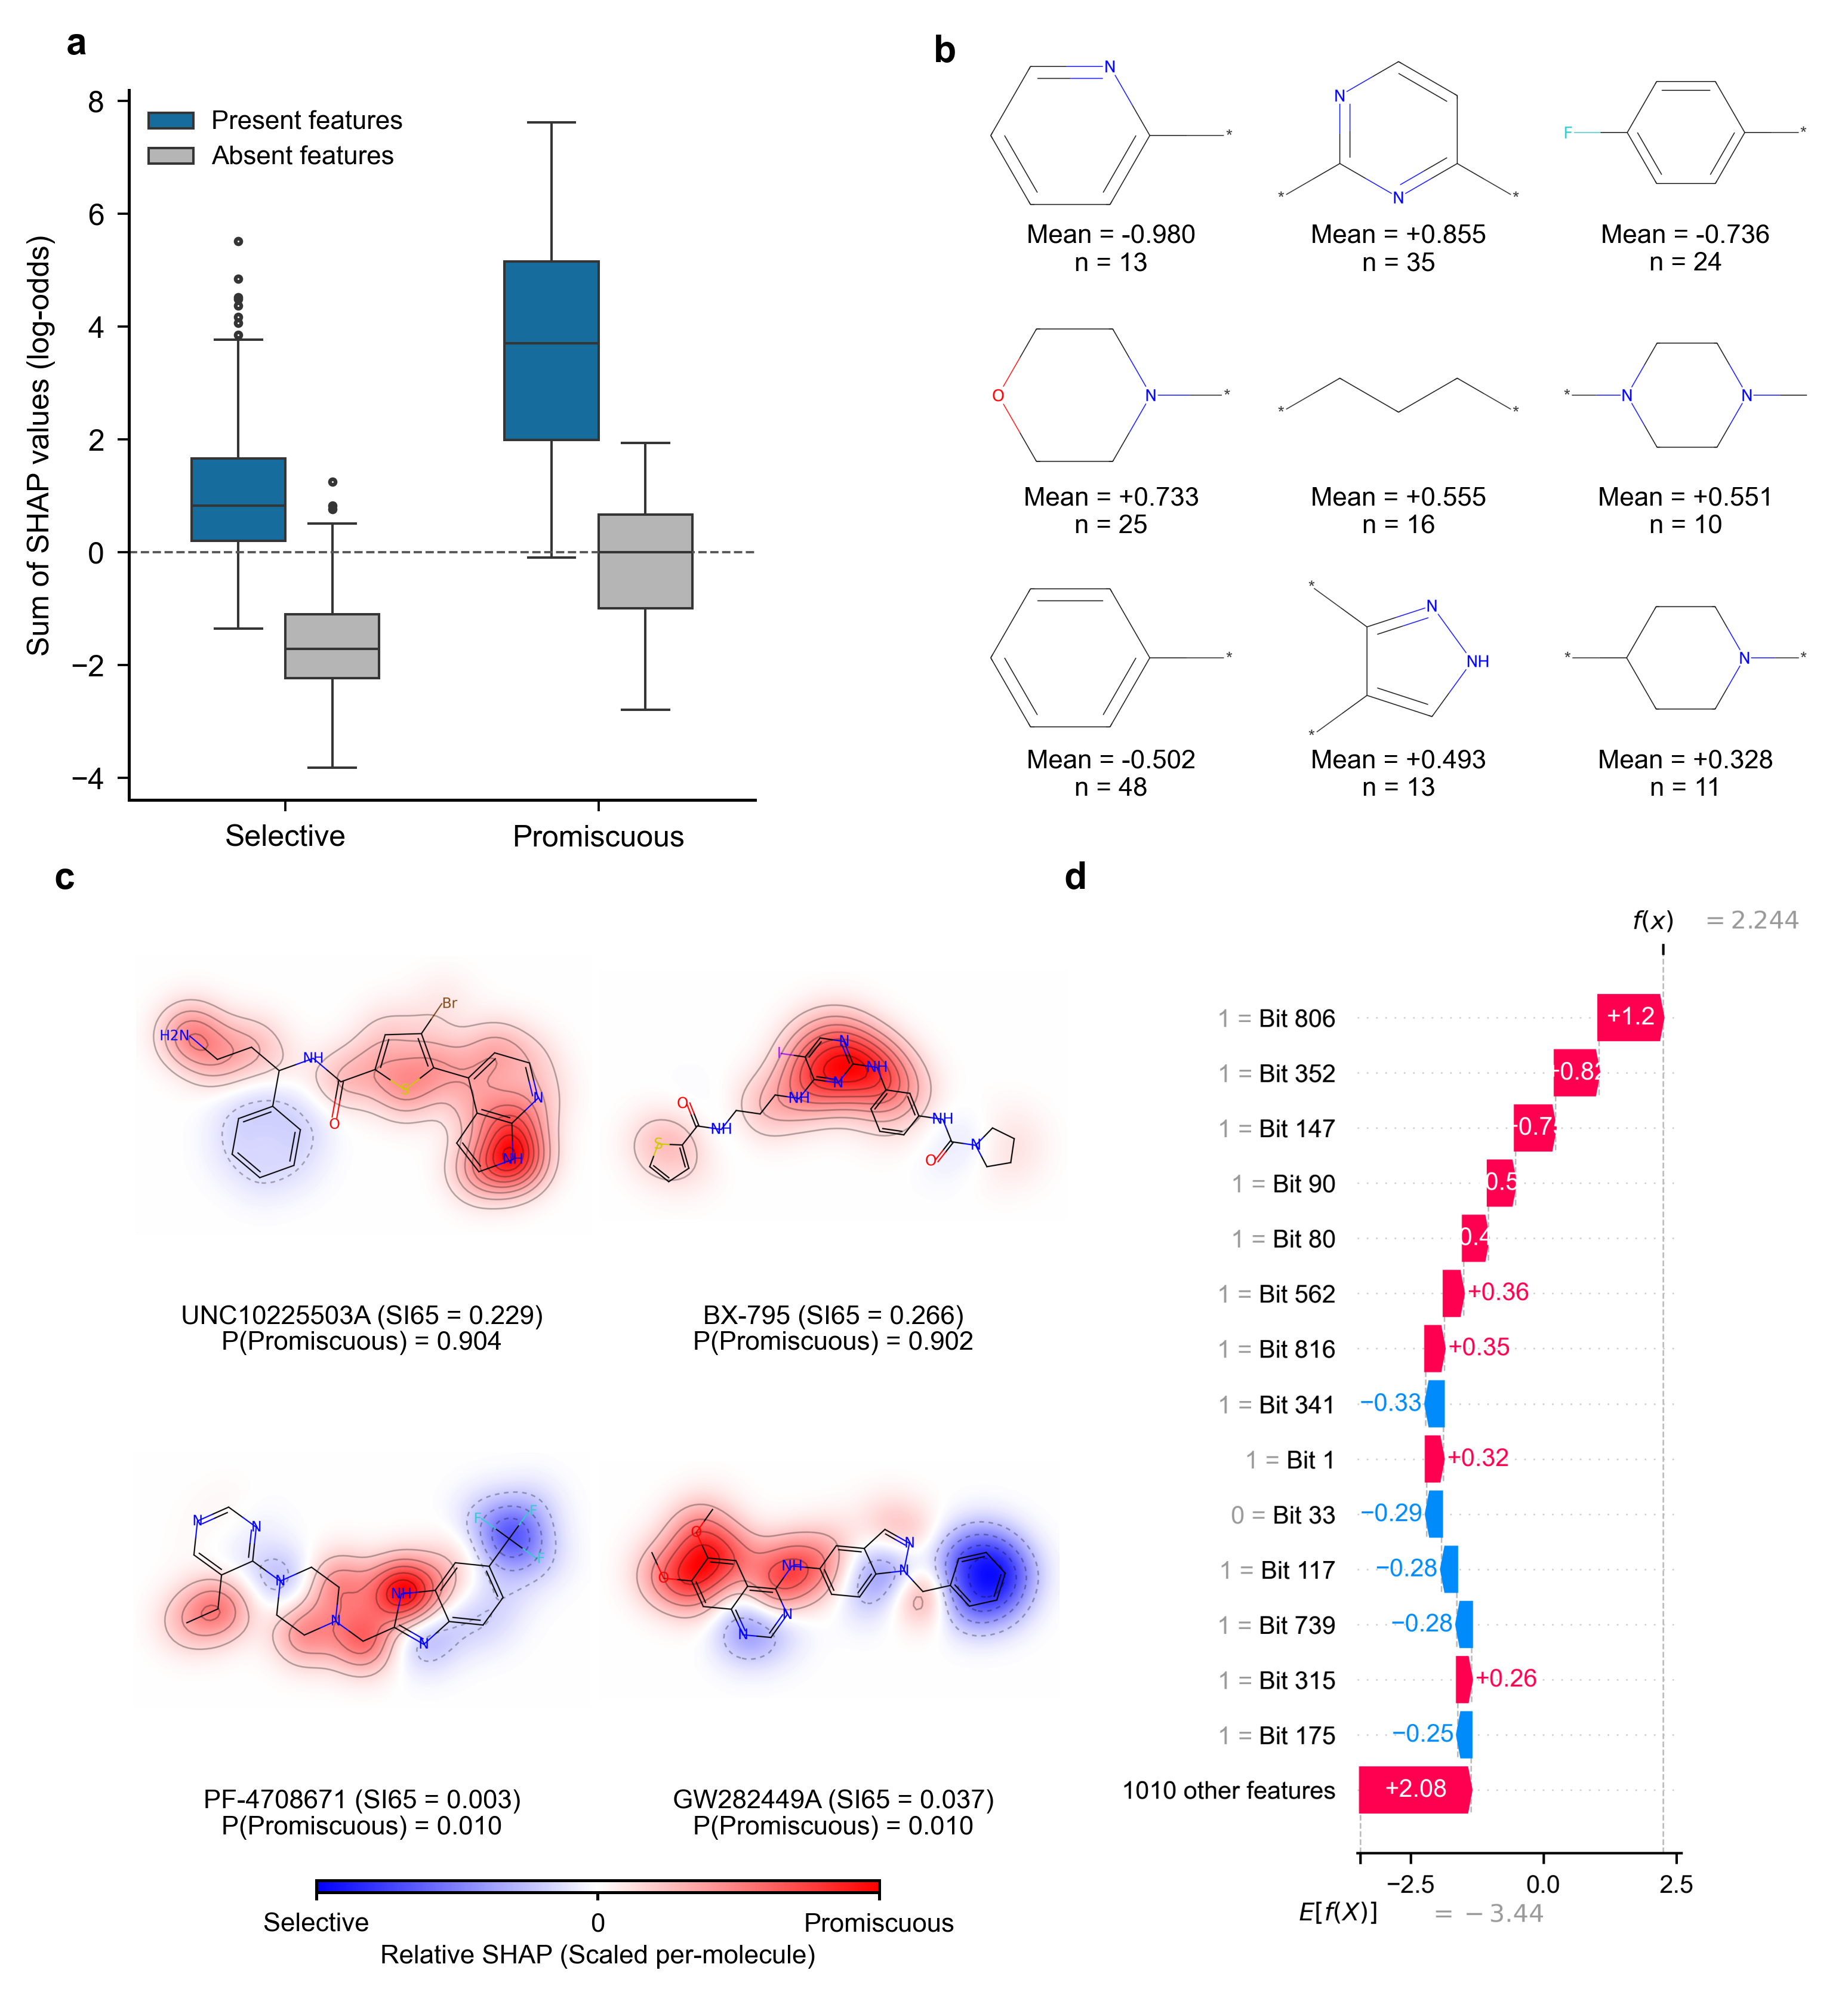

In [19]:
fig = plt.figure(figsize=(7.08, 7.4), facecolor='white')
grid = fig.add_gridspec(2, 1, height_ratios=[2.6, 3.7],
                        left=.10, right=.99, bottom=.04, top=.975, hspace=.16)
top_grid = grid[0].subgridspec(1, 2, width_ratios=[1, 1.35], wspace=.30)
bottom_grid = fig.add_gridspec(1, 2, width_ratios=[1.3, 1],
                               left=.10, right=.99, bottom=.04,
                               top=grid[1].get_position(fig).y1 + .025, wspace=.04)

ax_a = fig.add_subplot(top_grid[0, 0])
sns.boxplot(data=contribution_plot, x='Class', y='SHAP sum', hue='Feature status',
    order=['Selective', 'Promiscuous'], hue_order=['Present features', 'Absent features'],
    palette=[MAIN_COLORS['blue'], '#b5b5b5'], width=.6, linewidth=.65, fliersize=1.5, ax=ax_a)
ax_a.set_facecolor('white')
ax_a.grid(False, which='both')
ax_a.axhline(0, color='#555555', lw=.6, ls='--')
ax_a.set(xlabel='', ylabel=f'Sum of SHAP values ({SHAP_UNIT})')
ax_a.legend(title=None, frameon=False, loc='best', fontsize=6)
style_axis(ax_a, 'a')

ax_b = fig.add_subplot(top_grid[0, 1])
ax_b.axis('off')
ax_b.text(-.05, 1.04, 'b', transform=ax_b.transAxes, fontsize=9, fontweight='bold')
# Raise the fragments and captions without changing their size.
fragment_bounds = top_grid[0, 1].get_position(fig)
fragment_grid = fig.add_gridspec(3, 3, left=fragment_bounds.x0, right=fragment_bounds.x1,
                                 bottom=fragment_bounds.y0 + .025, top=fragment_bounds.y1 + .025,
                                 hspace=.42, wspace=.06)
for position, (smiles, row) in enumerate(figure8_fragments.iterrows()):
    ax = fig.add_subplot(fragment_grid[position // 3, position % 3])
    ax.imshow(Draw.MolToImage(fragment_molecules[smiles], size=(650, 420)))
    ax.axis('off')
    ax.text(.5, -.02, f'Mean = {row["Mean_Projected_SHAP"]:+.3f}\nn = {int(row["Compounds_N"])}',
            transform=ax.transAxes, ha='center', va='top', fontsize=6)

ax_c = fig.add_subplot(bottom_grid[0, 0])
ax_c.axis('off')
lower_panel_label_y = 1.00  # Lower both labels together; keep the panel contents in place.
ax_c.text(-.08, lower_panel_label_y, 'c', transform=ax_c.transAxes, fontsize=9, fontweight='bold')
map_grid = bottom_grid[0, 0].subgridspec(5, 2, height_ratios=[1, .16, 1, .16, .22],
                                      hspace=.01, wspace=.01)
for position, idx in enumerate(example_indices):
    row, col = 2 * (position // 2), position % 2
    ax = fig.add_subplot(map_grid[row, col])
    # Trim near-white image margins so each compound fills more of its existing slot.
    heatmap = heatmap_images[idx]
    occupied_y, occupied_x = np.nonzero(np.any(heatmap[..., :3] < 250, axis=-1))
    if occupied_x.size:
        pad = max(2, int(.025 * max(np.ptp(occupied_x) + 1, np.ptp(occupied_y) + 1)))
        x0, x1 = max(0, occupied_x.min() - pad), min(heatmap.shape[1], occupied_x.max() + pad + 1)
        y0, y1 = max(0, occupied_y.min() - pad), min(heatmap.shape[0], occupied_y.max() + pad + 1)
        heatmap = heatmap[y0:y1, x0:x1]
    ax.imshow(heatmap)
    ax.axis('off')
    label_ax = fig.add_subplot(map_grid[row + 1, col])
    label_ax.axis('off')
    compound = df_test.iloc[idx]
    label_ax.text(.5, 1., f'{compound["Compound ID"]} (SI65 = {compound["SI65"]:.3f})\n'
                          f'P(Promiscuous) = {y_pred_proba[idx]:.3f}',
                  transform=label_ax.transAxes, ha='center', va='top', fontsize=6, linespacing=1.1)
legend_ax = fig.add_subplot(map_grid[4, :])
legend_ax.axis('off')
cax = legend_ax.inset_axes([.20, .62, .60, .13])
bar = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-1, 1), cmap=SHAP_COLORMAP),
                   cax=cax, orientation='horizontal', ticks=[-1, 0, 1])
bar.set_ticklabels(['Selective', '0', 'Promiscuous'])
bar.set_label('Relative SHAP (Scaled per-molecule)', fontsize=6, labelpad=2)
bar.ax.tick_params(labelsize=6, length=2)

ax_d = fig.add_subplot(bottom_grid[0, 1])
ax_d.imshow(waterfall_image, aspect='auto')
ax_d.axis('off')
ax_d.text(-.05, lower_panel_label_y, 'd', transform=ax_d.transAxes, fontsize=9, fontweight='bold')
for text in fig.findobj(match=Text):
    text.set_fontsize(text.get_fontsize() + 1)
save_figure(fig, DIRS['figures_main'], 'Figure_8_Model_Interpretation')
plt.show()

## Alternative promiscuity definitions

In [20]:
raw_df = pd.read_csv(Path(DATA_DIR) / 'KIPS_Dataset.csv')
uncharger = rdMolStandardize.Uncharger()

def standardized_key(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    return Chem.MolToInchiKey(uncharger.uncharge(rdMolStandardize.ChargeParent(mol)))

raw_df['InChI_Key'] = raw_df['SMILES'].map(standardized_key)
raw_df = raw_df.dropna(subset=['InChI_Key']).drop_duplicates('InChI_Key').set_index('InChI_Key')
kinase_cols = [col for col in raw_df if col not in ('Compound ID', 'SMILES') and '-' not in col]
activity = raw_df.loc[kips_df['InChI_Key'], kinase_cols].apply(pd.to_numeric, errors='coerce')
activity = np.clip(np.nan_to_num(activity.to_numpy(), nan=0.), 0., 100.)
robustness_metrics = pd.DataFrame({f'SI{cutoff}': (activity >= cutoff).mean(axis=1)
                                  for cutoff in (50, 65, 90)}, index=kips_df.index)
np.testing.assert_allclose(robustness_metrics['SI65'], kips_df['SI65'])

robustness_definitions = {}
for metric in ('SI50', 'SI65', 'SI90'):
    ordered = np.sort(robustness_metrics[metric])
    knee = KneeLocator(np.arange(len(ordered)), ordered, curve='convex', direction='increasing',
                       S=KNEEDLE_SENSITIVITY)
    if knee.knee_y is None:
        raise ValueError(f'No Kneedle cutoff for {metric}; inspect the metric distribution.')
    robustness_definitions[metric] = float(knee.knee_y)
np.testing.assert_array_equal(robustness_metrics['SI65'].ge(robustness_definitions['SI65']),
                              kips_df[TARGET_COL].astype(bool))

## Robustness models

In [21]:
X_all = fingerprint_matrix(kips_df['mol'], SELECTED_FP_CONFIG)
robustness_scores, robustness_directions = {}, {}
compound_splits = kips_df[['Compound ID', SMILES_COL]].rename(columns={SMILES_COL: 'SMILES'}).copy()
for definition, cutoff in robustness_definitions.items():
    folder = DIRS['robustness'] / definition
    folder.mkdir(parents=True, exist_ok=True)
    labels = robustness_metrics[definition].ge(cutoff).to_numpy(dtype=int)
    train_idx, test_idx = train_test_split(np.arange(len(labels)), test_size=.2,
                                          stratify=labels, random_state=RANDOM_SEED)
    compound_splits[definition] = 'Train'
    compound_splits.loc[test_idx, definition] = 'Test'
    scenario_y_train, scenario_y_test = labels[train_idx], labels[test_idx]
    scenario_X_train, scenario_X_test = X_all[train_idx], X_all[test_idx]
    scenario_folds = list(skf.split(scenario_X_train, scenario_y_train))
    scenario_study = optuna.create_study(direction='maximize', study_name=definition,
                                        sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED, multivariate=True))
    scenario_study.optimize(partial(classifier_objective, matrix=scenario_X_train,
        labels=scenario_y_train, folds=scenario_folds), n_trials=N_ROBUSTNESS_TRIALS, show_progress_bar=True)
    scenario_params = classifier_trial_params(optuna.trial.FixedTrial(scenario_study.best_params))
    scenario_oof = oof_predictions(scenario_X_train, scenario_y_train, scenario_params, scenario_folds)
    scenario_threshold, _, _ = select_decision_threshold(scenario_y_train, scenario_oof)
    scenario_model = make_classifier('XGBoost', scenario_y_train, scenario_params)
    scenario_model.fit(scenario_X_train, scenario_y_train)
    scenario_proba = scenario_model.predict_proba(scenario_X_test)[:, 1]
    test_metrics = calc_metrics(scenario_y_test, scenario_proba, scenario_threshold)
    scenario_explanation = explain_classifier(scenario_model, scenario_X_test, scenario_X_train)
    present = scenario_X_test > 0
    present_n = present.sum(axis=0)
    signed_present = np.divide((scenario_explanation.values * present).sum(axis=0),
        present_n, out=np.full(SELECTED_NBITS, np.nan), where=present_n > 0)
    robustness_directions[definition] = signed_present
    robustness_scores[definition] = {
        'Train Size': len(train_idx), 'Train Prevalence': scenario_y_train.mean(),
        'Test Size': len(test_idx), 'Test Prevalence': scenario_y_test.mean(),
        'Kneedle Threshold': cutoff, 'OOF MCC-defined Threshold': scenario_threshold,
        **{key.replace('_', '-'): value for key, value in test_metrics.items()},
    }
    pd.Series(test_metrics, name='Value').rename({'ROC_AUC': 'ROC-AUC', 'PR_AUC': 'PR-AUC'}).rename_axis(
        'Metric').to_csv(folder / 'Test_Metrics.csv')

    scenario_model.save_model(folder / 'Model.json')
    scenario_study.trials_dataframe().to_csv(folder / 'Optuna_Trials.csv', index=False)
    (folder / 'Configuration.json').write_text(json.dumps({
        'definition': definition, 'metric_cutoff': cutoff, 'cutoff_method': 'Kneedle on curated cohort',
        'fingerprint': SELECTED_FP_CONFIG, 'params': scenario_params, 'seed': RANDOM_SEED,
        'optuna_trials': N_ROBUSTNESS_TRIALS, 'CV_folds': N_FOLDS, 'test_size': .2,
        'prediction_threshold': scenario_threshold, 'CV_PR_AUC': scenario_study.best_value,
    }, indent=2))
    fold_ids = np.empty(len(train_idx), dtype=int)
    for fold, (_, val_idx) in enumerate(scenario_folds):
        fold_ids[val_idx] = fold
    pd.concat([
        kips_df.iloc[train_idx][['Compound ID', 'InChI_Key']].assign(
            Split='Train', Label=scenario_y_train, CV_fold=fold_ids),
        kips_df.iloc[test_idx][['Compound ID', 'InChI_Key']].assign(
            Split='Test', Label=scenario_y_test, CV_fold=-1),
    ]).to_csv(folder / 'Split_Assignments.csv', index=False)
    pd.DataFrame({'Compound ID': kips_df.iloc[train_idx]['Compound ID'], 'Label': scenario_y_train,
                  'CV_fold': fold_ids, 'OOF_probability': scenario_oof}).to_csv(
        folder / 'OOF_Predictions.csv', index=False)
    pd.DataFrame({'Compound ID': kips_df.iloc[test_idx]['Compound ID'], 'Label': scenario_y_test,
                  'Probability': scenario_proba, 'Prediction': (scenario_proba >= scenario_threshold).astype(int)
                 }).to_csv(folder / 'Test_Predictions.csv', index=False)
    np.savez_compressed(folder / 'Test_SHAP.npz', values=scenario_explanation.values,
        base_values=scenario_explanation.base_values, test_inchi_keys=kips_df.iloc[test_idx]['InChI_Key'].to_numpy(dtype=str))

c:\Users\bstrickland\miniconda3\envs\KIPS\lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  optuna_warn(
Best trial: 174. Best value: 0.660736: 100%|██████████| 500/500 [2:37:08<00:00, 18.86s/it]  
c:\Users\bstrickland\miniconda3\envs\KIPS\lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  optuna_warn(
Best trial: 130. Best value: 0.632129: 100%|██████████| 500/500 [3:04:17<00:00, 22.12s/it]  
c:\Users\bstrickland\miniconda3\envs\KIPS\lib\site-packages\optuna\_experimental.py:33: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  optuna_warn(
Best trial: 83. Best value: 0.622726: 100%|██████████| 500/500 [2:35:29<00:00, 18.66s/it]  


## Robustness tables

Prevalences are fractions. SHAP values are mean signed log-odds when present; NA denotes no test-set occurrences.

In [22]:
definitions = ['SI50', 'SI65', 'SI90']
compound_splits = compound_splits[['Compound ID', 'SMILES', *definitions]]
compound_splits.to_csv(DIRS['tables_data'] / 'Supplementary_Data_Table_11_Data_Splits.csv', index=False)

performance_table = pd.DataFrame(robustness_scores).reindex(columns=definitions).rename_axis('Metric')
performance_table.drop(index='Accuracy').apply(
    lambda row: row.map('{:.0f}'.format if 'Size' in row.name else '{:.3f}'.format), axis=1
).to_csv(DIRS['tables_information'] / 'Supplementary_Table_6_Alternative_Definitions.csv')

shap_table = pd.DataFrame(robustness_directions, index=pd.Index(range(SELECTED_NBITS), name='FP Bit'))
shap_table = shap_table[definitions]
(shap_table.round(3) + 0.0).to_csv(DIRS['tables_data'] / 'Supplementary_Data_Table_13_Fingerprint_SHAP.csv', na_rep='NA', float_format='%.3f')
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(performance_table)

,SI50,SI65,SI90
Metric,,,
Train Size,1230.000,1230.000,1230.000
Train Prevalence,0.115,0.115,0.096
Test Size,308.000,308.000,308.000
Test Prevalence,0.114,0.114,0.097
Kneedle Threshold,0.192,0.142,0.082
OOF MCC-defined Threshold,0.575,0.375,0.475
ROC-AUC,0.877,0.856,0.783
PR-AUC,0.670,0.631,0.497
Accuracy,0.922,0.893,0.916
